# DMV Practical 5: Air Quality Index (AQI) Analysis
**Aim:** Clean air-quality data and analyze pollution levels using Pandas, Matplotlib, and Seaborn.

**Dataset required:** `aqi_data.csv` (upload it to the same folder or to Google Colab).

In [11]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load dataset
data = pd.read_csv('aqi_data.csv')
data

,Date,Time,PM2.5,PM10,NO2,CO,O3,SO2,AQI Value,AQI Category,Location
0,2026-01-01,08:00,96.03,159.31,40.67,1.73,29.89,11.06,130,Moderate,Nashik Road
1,2026-01-01,08:00,118.02,190.44,30.89,1.42,27.83,10.14,145,Moderate,Panchavati
2,2026-01-01,08:00,90.85,98.29,19.91,1.07,22.88,13.26,97,Satisfactory,Satpur
3,2026-01-01,08:00,67.49,115.51,47.82,1.18,32.61,6.30,106,Moderate,Gangapur Road
4,2026-01-01,12:00,53.91,120.87,17.95,0.98,26.59,10.83,77,Satisfactory,Nashik Road
...,...,...,...,...,...,...,...,...,...,...,...
2875,2026-06-29,16:00,24.09,77.98,29.04,0.98,25.54,14.64,55,Satisfactory,Gangapur Road
2876,2026-06-29,20:00,46.20,111.04,40.70,1.39,25.92,16.79,86,Satisfactory,Nashik Road
2877,2026-06-29,20:00,59.63,128.93,48.38,1.60,42.08,12.77,104,Moderate,Panchavati
2878,2026-06-29,20:00,69.40,116.56,24.42,1.34,34.31,14.33,91,Satisfactory,Satpur


In [13]:

data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_')
data

,date,time,pm2.5,pm10,no2,co,o3,so2,aqi_value,aqi_category,location
0,2026-01-01,08:00,96.03,159.31,40.67,1.73,29.89,11.06,130,Moderate,Nashik Road
1,2026-01-01,08:00,118.02,190.44,30.89,1.42,27.83,10.14,145,Moderate,Panchavati
2,2026-01-01,08:00,90.85,98.29,19.91,1.07,22.88,13.26,97,Satisfactory,Satpur
3,2026-01-01,08:00,67.49,115.51,47.82,1.18,32.61,6.30,106,Moderate,Gangapur Road
4,2026-01-01,12:00,53.91,120.87,17.95,0.98,26.59,10.83,77,Satisfactory,Nashik Road
...,...,...,...,...,...,...,...,...,...,...,...
2875,2026-06-29,16:00,24.09,77.98,29.04,0.98,25.54,14.64,55,Satisfactory,Gangapur Road
2876,2026-06-29,20:00,46.20,111.04,40.70,1.39,25.92,16.79,86,Satisfactory,Nashik Road
2877,2026-06-29,20:00,59.63,128.93,48.38,1.60,42.08,12.77,104,Moderate,Panchavati
2878,2026-06-29,20:00,69.40,116.56,24.42,1.34,34.31,14.33,91,Satisfactory,Satpur


In [ ]:

# Standardize common column names
data = data.rename(columns={
    'pm2_5': 'pm25', 'pm2.5': 'pm25', 'rspm': 'pm10',
    'from_date': 'date', 'sampling_date': 'date',
    'station': 'location', 'aqi': 'aqi_value'
})

print('First 5 rows:')
display(data.head())
print('Dataset shape:', data.shape)
data.info()

In [3]:
# 3. Clean the data
print('Missing values before cleaning:')
print(data.isnull().sum())

data = data.drop_duplicates()

# Find pollutant columns that exist in this dataset
pollutants = [c for c in ['pm25', 'pm10', 'no2', 'co', 'o3', 'so2'] if c in data.columns]

for col in pollutants:
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data[col] = data[col].fillna(data[col].mean())

print('\nPollutant columns:', pollutants)
print('Missing values after cleaning:')
print(data.isnull().sum())

Missing values before cleaning:
date            0
time            0
pm25            0
pm10            0
no2             0
co              0
o3              0
so2             0
aqi_value       0
aqi_category    0
location        0
dtype: int64

Pollutant columns: ['pm25', 'pm10', 'no2', 'co', 'o3', 'so2']
Missing values after cleaning:
date            0
time            0
pm25            0
pm10            0
no2             0
co              0
o3              0
so2             0
aqi_value       0
aqi_category    0
location        0
dtype: int64


In [4]:
# 4. Prepare dates and seasons
if 'date' in data.columns:
    data['date'] = pd.to_datetime(data['date'], errors='coerce')
    data['year'] = data['date'].dt.year
    data['month'] = data['date'].dt.month

    def get_season(month):
        if month in [3, 4, 5]:
            return 'Summer'
        elif month in [6, 7, 8, 9]:
            return 'Monsoon'
        elif month in [10, 11]:
            return 'Post-Monsoon'
        return 'Winter'

    data['season'] = data['month'].apply(get_season)
    print(data[['date', 'year', 'month', 'season']].head())
else:
    print('No date column found; date-based analysis will be skipped.')

        date  year  month  season
0 2026-01-01  2026      1  Winter
1 2026-01-01  2026      1  Winter
2 2026-01-01  2026      1  Winter
3 2026-01-01  2026      1  Winter
4 2026-01-01  2026      1  Winter


Average pollutant levels:
pm25     62.691500
pm10    119.911986
no2      30.056747
co        1.071306
o3       31.939674
so2      12.036715
dtype: float64

Maximum pollutant levels:
pm25    139.17
pm10    273.83
no2      62.63
co        2.65
o3       62.40
so2      27.41
dtype: float64


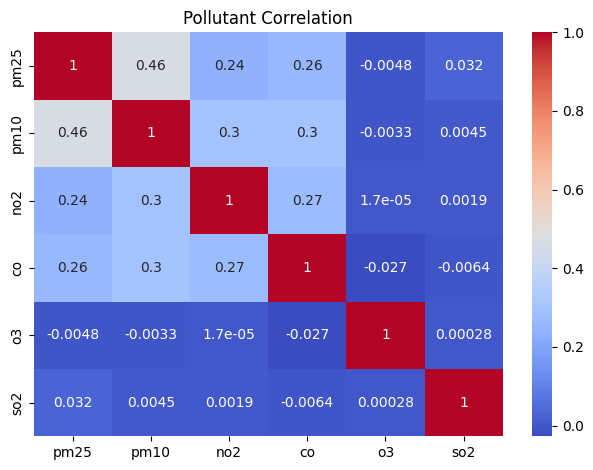

In [5]:
# 5. Analyze pollutant averages
if pollutants:
    print('Average pollutant levels:')
    print(data[pollutants].mean())
    print('\nMaximum pollutant levels:')
    print(data[pollutants].max())

    # Correlation heatmap
    sns.heatmap(data[pollutants].corr(), annot=True, cmap='coolwarm')
    plt.title('Pollutant Correlation')
    plt.tight_layout()
    plt.show()
else:
    print('No recognized pollutant columns found. Check data.columns.')

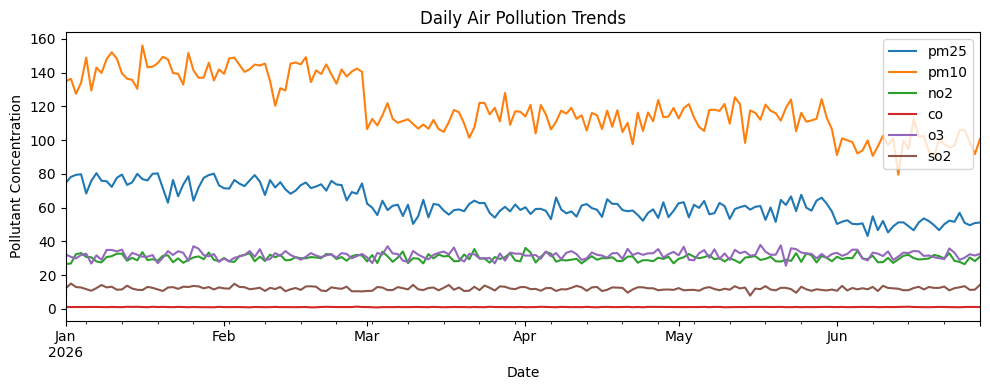

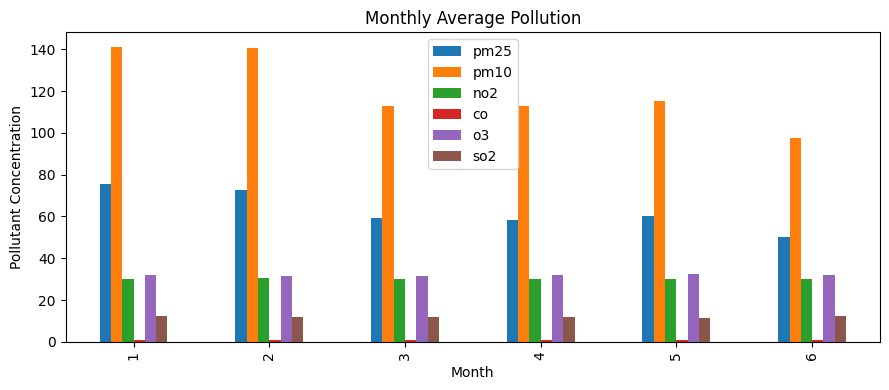

In [6]:
# 6. Plot daily and monthly pollution trends
if pollutants and 'date' in data.columns:
    data.groupby('date')[pollutants].mean().plot(figsize=(10, 4))
    plt.title('Daily Air Pollution Trends')
    plt.xlabel('Date')
    plt.ylabel('Pollutant Concentration')
    plt.tight_layout()
    plt.show()

    if 'month' in data.columns:
        data.groupby('month')[pollutants].mean().plot(kind='bar', figsize=(9, 4))
        plt.title('Monthly Average Pollution')
        plt.xlabel('Month')
        plt.ylabel('Pollutant Concentration')
        plt.tight_layout()
        plt.show()

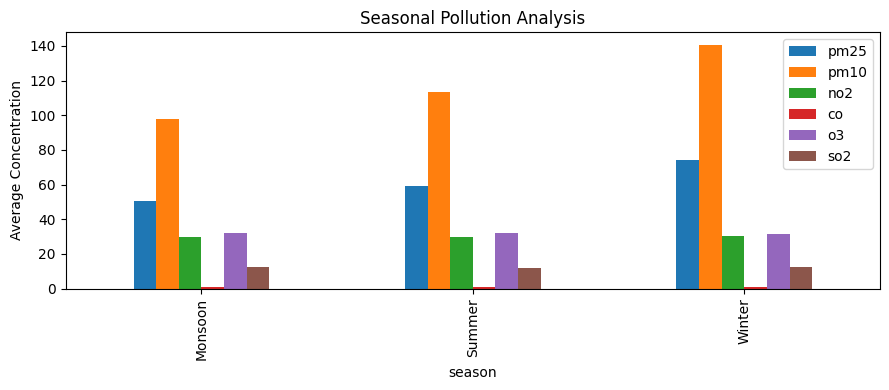

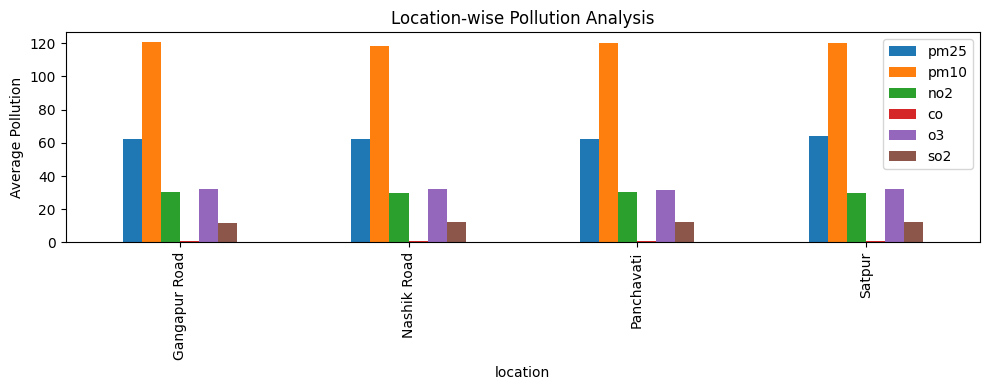

In [7]:
# 7. Seasonal and location-wise analysis
if pollutants and 'season' in data.columns:
    data.groupby('season')[pollutants].mean().plot(kind='bar', figsize=(9, 4))
    plt.title('Seasonal Pollution Analysis')
    plt.ylabel('Average Concentration')
    plt.tight_layout()
    plt.show()

if pollutants and 'location' in data.columns:
    data.groupby('location')[pollutants].mean().plot(kind='bar', figsize=(10, 4))
    plt.title('Location-wise Pollution Analysis')
    plt.ylabel('Average Pollution')
    plt.tight_layout()
    plt.show()

Average AQI: 91.26840277777778


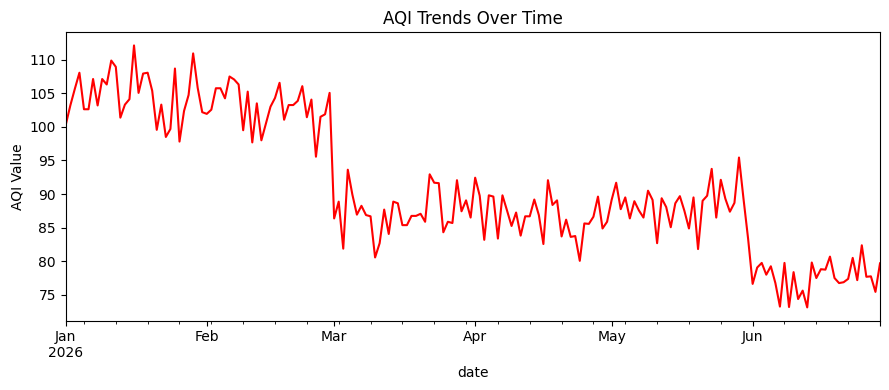

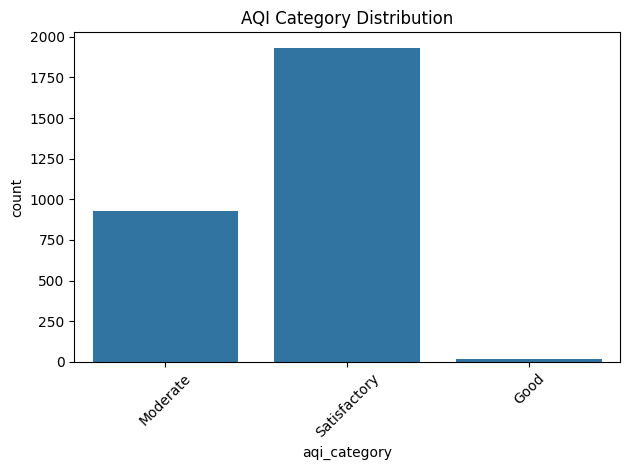

In [8]:
# 8. Analyze AQI and category (if columns exist)
if 'aqi_value' in data.columns:
    data['aqi_value'] = pd.to_numeric(data['aqi_value'], errors='coerce')
    print('Average AQI:', data['aqi_value'].mean())
    if 'date' in data.columns:
        data.groupby('date')['aqi_value'].mean().plot(color='red', figsize=(9, 4))
        plt.title('AQI Trends Over Time')
        plt.ylabel('AQI Value')
        plt.tight_layout()
        plt.show()
else:
    print('AQI value column not available.')

if 'aqi_category' in data.columns:
    sns.countplot(data=data, x='aqi_category')
    plt.title('AQI Category Distribution')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('AQI category column not available.')

In [9]:
# 9. Save cleaned dataset
data.to_csv('cleaned_aqi_data.csv', index=False)
print('Cleaned data saved as cleaned_aqi_data.csv')
print('AQI analysis completed successfully!')

Cleaned data saved as cleaned_aqi_data.csv
AQI analysis completed successfully!
